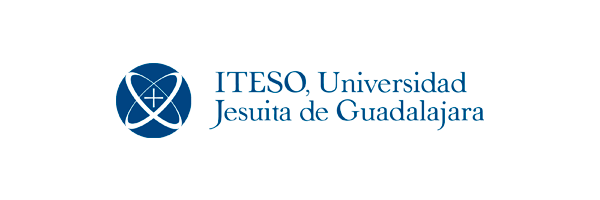

# Proyecto 2. Práctica de Redes Neuronales Estáticas

## Predicción del riesgo de quiebra de empresas

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 12 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Departamento:** Matemáticas y Física

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción](#introduccion)
2. [Objetivos](#objetivos)
3. [Base de datos](#base-datos)
4. [Tratamiento previo y normalización](#tratamiento)
    - 4.1 [¿Qué es la normalización y para qué sirve?](#que-es-normalizacion)
    - 4.2 [Método utilizado](#metodo)
    - 4.3 [Implementación](#implementacion-tratamiento)
    - 4.4 [Resultados del tratamiento](#resultados-tratamiento)
5. [Archivos de datos tratados](#archivos)
6. [Modelo no supervisado: Red Competitiva](#red-competitiva)
    - 6.1 [Fundamento de la red competitiva](#fundamento-rc)
    - 6.2 [Variables de entrada de la red](#variables-rc)
    - 6.3 [Implementación](#implementacion-rc)
    - 6.4 [Justificación del número de neuronas](#neuronas-rc)
    - 6.5 [Entrenamiento de la red final](#entrenamiento-rc)
    - 6.6 [Análisis a posteriori de las etiquetas](#posteriori-rc)
    - 6.7 [Medidas de desempeño](#desempeno-rc)
    - 6.8 [Modelo final y uso para empresas nuevas](#modelo-rc)

<a id="introduccion"></a>

## 1. Introducción

Predecir si una empresa puede caer en **quiebra** (*default*) es una de las aplicaciones más importantes de la clasificación en finanzas. Bancos, inversionistas y reguladores necesitan identificar a tiempo a las empresas en riesgo, y para eso cuentan con sus **razones financieras**: rentabilidad, liquidez, endeudamiento, rotación de activos, entre otras.

Existen dos formas de abordar el problema:

- **Clasificación no supervisada:** se agrupan las empresas solo por la similitud de sus razones financieras, sin saber cuáles quebraron. En este proyecto se hace con una **red competitiva**, donde cada neurona representa un grupo de empresas con características parecidas.
- **Clasificación supervisada:** se entrena un modelo con la etiqueta real de quiebra para aprender una regla que clasifique empresas nuevas. Para esto se usa una red **ADALINE** o **perceptrón**.

Antes de entrenar cualquier red hay que **tratar los datos**. Las razones financieras vienen en escalas muy distintas y algunas traen valores extremos que, si no se corrigen, dominan el entrenamiento y empeoran los resultados. Por eso, este documento comienza con la obtención de la base de datos y su tratamiento previo, que sirven de base para los modelos de las siguientes secciones.

<a id="objetivos"></a>

## 2. Objetivos

**Objetivo general:** construir clasificadores basados en redes neuronales estáticas (supervisados y no supervisados) que permitan identificar si una empresa tiene riesgo de irse a la quiebra a partir de sus razones financieras.

**Objetivos específicos**

1. Obtener una base de datos pública de empresas con al menos 500 registros y 10 razones financieras, y preparar los datos con un tratamiento previo y una normalización adecuados.
2. Seleccionar las variables que más influyen en la quiebra y justificar la selección.
3. Agrupar las empresas con una **red competitiva** y analizar cómo se distribuyen las empresas en quiebra dentro de cada grupo.
4. Entrenar una red **ADALINE o perceptrón** con la etiqueta real de quiebra y medir su desempeño (exactitud, precisión y *recall*).
5. Usar los dos mejores modelos para predecir si 5 empresas nuevas, no vistas en el entrenamiento, tienen riesgo de quiebra.

<a id="base-datos"></a>

## 3. Base de datos

| Característica | Detalle |
|---|---|
| Nombre | *Taiwanese Bankruptcy Prediction* |
| Fuente | UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction |
| Origen de los datos | *Taiwan Economic Journal*, empresas de Taiwán de 1999 a 2009 |
| Registros | 6 819 empresas (requisito: al menos 500) |
| Variables | 95 razones financieras (requisito: al menos 10) |
| Etiqueta | `Bankrupt?` → 1 = quiebra, 0 = sana. Una empresa se considera en quiebra según las reglas de la Bolsa de Taiwán |

**¿Por qué esta base?** Es pública, es de las más usadas en la literatura de predicción de quiebra, supera por mucho los requisitos de tamaño y trae la etiqueta real de quiebra, que se necesita para el modelo supervisado y para revisar los grupos de la red competitiva.

Las variables cubren las principales familias de razones financieras: **rentabilidad** (ROA, márgenes, utilidad por acción), **liquidez** (razón circulante, prueba ácida, efectivo / pasivo circulante), **endeudamiento** (deuda / capital, dependencia de préstamos), **actividad** (rotación de inventarios, de cuentas por cobrar, de activos) y **crecimiento** (crecimiento de activos, de capital, de utilidades).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Rutas del repositorio (el notebook está en la carpeta raíz)
ruta_cruda = Path("datos/crudos/taiwan_bankruptcy.csv")
carpeta_tratados = Path("datos/tratados")
carpeta_img = Path("img")
carpeta_tratados.mkdir(parents=True, exist_ok=True)
carpeta_img.mkdir(parents=True, exist_ok=True)

semilla = 42             # Semilla fija: todo el equipo obtiene la misma división
col_objetivo = "quiebra"

# Lectura y limpieza de nombres de columnas
datos = pd.read_csv(ruta_cruda)
datos.columns = datos.columns.str.strip()                    # Quitar espacios sobrantes
datos = datos.rename(columns={"Bankrupt?": col_objetivo})    # 1 = quiebra, 0 = sana

print(f"Empresas: {datos.shape[0]} | Variables: {datos.shape[1] - 1}")
datos.head()

Empresas: 6819 | Variables: 95


,quiebra,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [2]:
# Revisión de calidad de los datos
faltantes = int(datos.isna().sum().sum())
duplicados = int(datos.duplicated().sum())
constantes = [col for col in datos.columns if datos[col].nunique() <= 1]
binarias = [col for col in datos.columns if datos[col].nunique() == 2 and col != col_objetivo]

print(f"Datos faltantes: {faltantes}")
print(f"Filas duplicadas: {duplicados}")
print(f"Variables constantes (no aportan información): {constantes}")
print(f"Variables binarias (0/1): {binarias}")

conteo = datos[col_objetivo].value_counts().sort_index()
print(f"\nEmpresas sanas: {conteo[0]} | Empresas en quiebra: {conteo[1]} ({conteo[1] / len(datos):.2%})")

Datos faltantes: 0
Filas duplicadas: 0
Variables constantes (no aportan información): ['Net Income Flag']
Variables binarias (0/1): ['Liability-Assets Flag']

Empresas sanas: 6599 | Empresas en quiebra: 220 (3.23%)


In [3]:
# Variables con valores fuera de la escala 0-1 de la base
fuera_escala = (datos.drop(columns=col_objetivo) > 1).mean()
extremas = pd.DataFrame({"% de empresas con valor > 1": (fuera_escala * 100).round(2),
                         "Mediana": datos.drop(columns=col_objetivo).median(),
                         "Máximo": datos.drop(columns=col_objetivo).max()})
extremas = extremas[extremas["% de empresas con valor > 1"] > 0].sort_values("% de empresas con valor > 1")
print(f"Variables con valores mayores a 1: {len(extremas)} de {datos.shape[1] - 1}")
extremas.style.format({"% de empresas con valor > 1": "{:.2f}", "Mediana": "{:.4g}", "Máximo": "{:.3g}"})

Variables con valores mayores a 1: 24 de 95


,% de empresas con valor > 1,Mediana,Máximo
Current Ratio,0.01,0.01059,2.75e+09
Fixed Assets to Assets,0.01,0.1969,8.32e+09
Revenue per person,0.03,0.01862,8.81e+09
Net Value Growth Rate,0.03,0.000462,9.33e+09
Quick Assets/Current Liability,0.04,0.007909,8.82e+09
Revenue Per Share (Yuan ¥),0.07,0.02738,3.02e+09
Total debt/Total net worth,0.12,0.005546,9.94e+09
Quick Ratio,0.13,0.007412,9.23e+09
Allocation rate per person,0.18,0.007844,9.57e+09
Average Collection Days,0.26,0.006573,9.73e+09


**Hallazgos de la revisión**

- No hay datos faltantes ni empresas duplicadas.
- `Net Income Flag` vale 1 para todas las empresas, así que no distingue entre ellas y se elimina.
- `Liability-Assets Flag` es una variable binaria (0/1). Se conserva, pero no se recorta.
- La fuente entrega las razones financieras **ya escaladas entre 0 y 1**, pero **24 variables tienen valores de hasta $10^{10}$**. Estos valores no son consistentes con la escala de la base y hay que tratarlos. Hay dos casos (tabla siguiente):
    - En **16 variables** los valores mayores a 1 son pocos (menos del 5 % de las empresas). Se consideran errores de captura y se corrigen con la winsorización.
    - En **8 variables** entre el 18 % y el 88 % de las empresas tienen valores mayores a 1. La variable mezcla dos escalas distintas y no es confiable, así que se elimina.
- La base está **desbalanceada**: solo el 3.2 % de las empresas quebró. Esto se tiene que considerar al entrenar y evaluar los modelos, porque un modelo que diga "ninguna quiebra" ya tendría 96.8 % de exactitud.

<a id="tratamiento"></a>

## 4. Tratamiento previo y normalización

<a id="que-es-normalizacion"></a>

### 4.1 ¿Qué es la normalización y para qué sirve?

**Normalizar** es transformar los valores de cada variable para que todas queden en una escala comparable, sin cambiar la información que contienen. Sirve para:

- **Que ninguna variable domine por su tamaño.** En una red competitiva la neurona ganadora se elige por distancia euclidiana; si una variable va de 0 a $10^{10}$ y otra de 0 a 1, la distancia dependería casi solo de la primera.
- **Que el gradiente descendente converja.** En ADALINE y en el perceptrón, las variables con escalas muy distintas hacen que el gradiente "zigzaguee" o diverja; con todas en la misma escala la red aprende más rápido y es más estable.
- **Que los pesos se puedan comparar** entre variables.

Los métodos más comunes son:

| Método | Fórmula | Resultado |
|---|---|---|
| Min-Max | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ | Valores entre 0 y 1 |
| Z-score (estandarización) | $z = \dfrac{x - \mu}{\sigma}$ | Media 0 y desviación estándar 1 |

<a id="metodo"></a>

### 4.2 Método utilizado

Se aplicó un tratamiento en **cuatro pasos**:

1. **División de los datos antes de tratarlos.**
   - Primero se apartan **5 empresas nuevas** (2 en quiebra y 3 sanas) que no se usan en ningún entrenamiento y sirven para la predicción final del proyecto.
   - El resto se divide en **entrenamiento (80 %)** y **prueba (20 %)** de forma **estratificada**, es decir, con la misma proporción de quiebras en ambos.
   - Todos los parámetros del tratamiento se calculan **solo con los datos de entrenamiento** y se aplican igual a prueba y a las empresas nuevas. Así los datos de prueba no "se filtran" al entrenamiento y la evaluación es honesta.
2. **Eliminación de variables con escala inconsistente.** Se eliminan las variables en las que más del 5 % de las empresas del entrenamiento tienen valores mayores a 1, junto con `Net Income Flag`, que es constante.
3. **Winsorización (recorte de valores extremos).** Cada variable continua se recorta a sus **percentiles 1 y 99**, calculados con los valores válidos (entre 0 y 1) del entrenamiento. Un valor por debajo del percentil 1 se reemplaza por ese percentil, y uno por arriba del percentil 99 (incluidos los errores de $10^{10}$), por el percentil 99. Así se corrigen los valores extremos sin borrar empresas. Las variables binarias no se recortan.
4. **Normalización Z-score:** $z = \dfrac{x - \mu}{\sigma}$, con la media $\mu$ y la desviación estándar $\sigma$ del entrenamiento.

**¿Por qué Z-score y no Min-Max?**
- Min-Max usa el mínimo y el máximo, que justo en esta base son valores extremos; con ellos casi todas las empresas quedarían aplastadas cerca de 0.
- Z-score centra cada variable en 0. Esto ayuda a que ADALINE y el perceptrón converjan más rápido con gradiente descendente y a que la sigmoide no se sature.
- Es el método que se usó en las prácticas del curso, así que los modelos de las siguientes secciones pueden trabajar directamente con estos datos.

<a id="implementacion-tratamiento"></a>

### 4.3 Implementación

In [4]:
# 1. Eliminar variables constantes
datos = datos.drop(columns=constantes)

# 2a. Apartar 5 empresas nuevas (2 en quiebra y 3 sanas) para la predicción final
rng = np.random.default_rng(semilla)
idx_quiebra = rng.choice(datos.index[datos[col_objetivo] == 1], size=2, replace=False)
idx_sanas = rng.choice(datos.index[datos[col_objetivo] == 0], size=3, replace=False)
idx_nuevas = np.concatenate([idx_quiebra, idx_sanas])
nuevas = datos.loc[idx_nuevas]
resto = datos.drop(index=idx_nuevas)

# 2b. Entrenamiento (80 %) y prueba (20 %) con la misma proporción de quiebras
entrenamiento, prueba = train_test_split(resto, test_size=0.20, random_state=semilla,
                                         stratify=resto[col_objetivo])

resumen_division = pd.DataFrame({
    "Empresas": [len(entrenamiento), len(prueba), len(nuevas)],
    "En quiebra": [int(entrenamiento[col_objetivo].sum()), int(prueba[col_objetivo].sum()), int(nuevas[col_objetivo].sum())]},
    index=["Entrenamiento", "Prueba", "Empresas nuevas"])
resumen_division["% quiebra"] = (resumen_division["En quiebra"] / resumen_division["Empresas"] * 100).round(2)
resumen_division

,Empresas,En quiebra,% quiebra
Entrenamiento,5451,174,3.19
Prueba,1363,44,3.23
Empresas nuevas,5,2,40.00


In [5]:
# 2. Eliminar variables con escala inconsistente (más del 5 % de valores > 1 en entrenamiento)
porcentaje_fuera = (entrenamiento.drop(columns=col_objetivo) > 1).mean()
inconsistentes = porcentaje_fuera[porcentaje_fuera > 0.05].index.tolist()
print("Variables eliminadas por escala inconsistente:")
for col in inconsistentes:
    print(f"  - {col} ({porcentaje_fuera[col]:.1%} de valores > 1)")

entrenamiento = entrenamiento.drop(columns=inconsistentes)
prueba = prueba.drop(columns=inconsistentes)
nuevas = nuevas.drop(columns=inconsistentes)
variables = [col for col in entrenamiento.columns if col != col_objetivo]
continuas = [col for col in variables if col not in binarias]
print(f"\nVariables a usar: {len(variables)} ({len(continuas)} continuas y {len(binarias)} binaria)")

# 3. Winsorización: percentiles 1 y 99 de los valores válidos (0 a 1) del entrenamiento
validos = entrenamiento[continuas].where(entrenamiento[continuas] <= 1)
p_inf = validos.quantile(0.01)
p_sup = validos.quantile(0.99)

def winsorizar(df):
    salida = df.copy()
    salida[continuas] = salida[continuas].clip(lower=p_inf, upper=p_sup, axis=1)
    return salida

entrenamiento_w = winsorizar(entrenamiento)
prueba_w = winsorizar(prueba)
nuevas_w = winsorizar(nuevas)

# 4. Normalización Z-score con la media y la desviación del entrenamiento
media = entrenamiento_w[variables].mean()
desviacion = entrenamiento_w[variables].std(ddof=0)

def normalizar(df):
    salida = df.copy()
    salida[variables] = (salida[variables] - media) / desviacion
    return salida

entrenamiento_z = normalizar(entrenamiento_w)
prueba_z = normalizar(prueba_w)
nuevas_z = normalizar(nuevas_w)

# Comprobación: en entrenamiento cada variable debe quedar con media 0 y desviación 1
print(f"Media máxima (en valor absoluto): {entrenamiento_z[variables].mean().abs().max():.2e}")
print(f"Desviación estándar: entre {entrenamiento_z[variables].std(ddof=0).min():.4f} y {entrenamiento_z[variables].std(ddof=0).max():.4f}")

Variables eliminadas por escala inconsistente:
  - Operating Expense Rate (33.5% de valores > 1)
  - Research and development expense rate (59.2% de valores > 1)
  - Total Asset Growth Rate (88.1% de valores > 1)
  - Inventory Turnover Rate (times) (43.3% de valores > 1)
  - Fixed Assets Turnover Frequency (18.1% de valores > 1)
  - Current Asset Turnover Rate (18.3% de valores > 1)
  - Quick Asset Turnover Rate (35.3% de valores > 1)
  - Cash Turnover Rate (62.8% de valores > 1)

Variables a usar: 86 (85 continuas y 1 binaria)


Media máxima (en valor absoluto): 7.61e-13
Desviación estándar: entre 1.0000 y 1.0000


<a id="resultados-tratamiento"></a>

### 4.4 Resultados del tratamiento

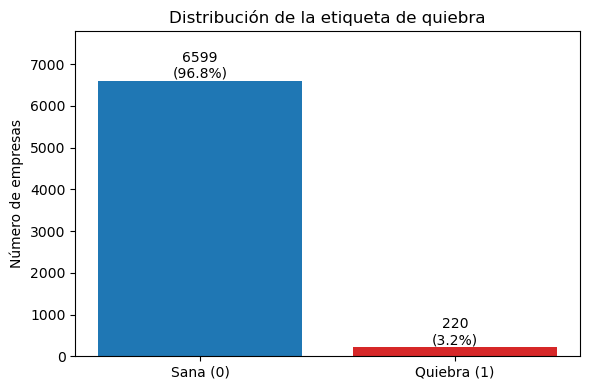

In [6]:
# Gráfica 1: distribución de la etiqueta de quiebra
plt.figure(figsize=(6, 4))
barras = plt.bar(["Sana (0)", "Quiebra (1)"], conteo.values, color=["tab:blue", "tab:red"])
for b, v in zip(barras, conteo.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / conteo.sum():.1%})", ha="center", va="bottom")
plt.ylabel("Número de empresas")
plt.title("Distribución de la etiqueta de quiebra")
plt.ylim(0, conteo.max() * 1.18)
plt.tight_layout()
plt.savefig(carpeta_img / "distribucion_clases.png", dpi=150)
plt.show()

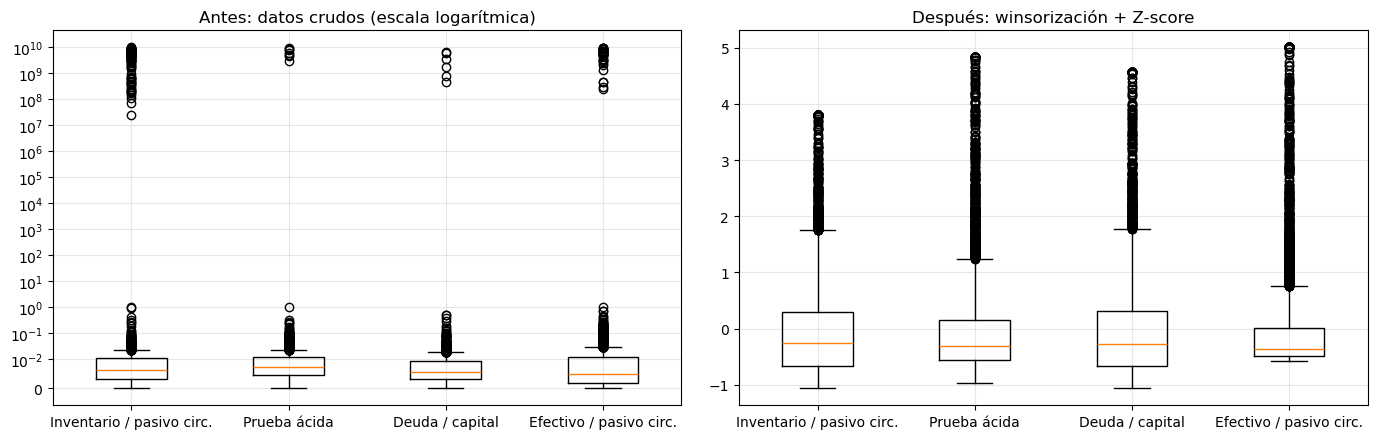

In [7]:
# Gráfica 2: antes y después del tratamiento, en 4 variables con valores extremos
ejemplo = ["Inventory/Current Liability", "Quick Ratio", "Total debt/Total net worth", "Cash/Current Liability"]
nombres_cortos = ["Inventario / pasivo circ.", "Prueba ácida", "Deuda / capital", "Efectivo / pasivo circ."]

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].boxplot([entrenamiento[v] for v in ejemplo])
axs[0].set_yscale("symlog", linthresh=1e-2)
axs[0].set_title("Antes: datos crudos (escala logarítmica)")
axs[1].boxplot([entrenamiento_z[v] for v in ejemplo])
axs[1].set_title("Después: winsorización + Z-score")
for ax in axs:
    ax.set_xticks(range(1, len(ejemplo) + 1), nombres_cortos)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(carpeta_img / "antes_despues_tratamiento.png", dpi=150)
plt.show()

In [8]:
# Tabla: rango de esas variables antes y después
comparacion = pd.DataFrame({
    "Máximo crudo": entrenamiento[ejemplo].max(),
    "Mediana cruda": entrenamiento[ejemplo].median(),
    "Mínimo tratado (z)": entrenamiento_z[ejemplo].min(),
    "Máximo tratado (z)": entrenamiento_z[ejemplo].max()})
comparacion.index = nombres_cortos
comparacion.style.format("{:.4g}")

,Máximo crudo,Mediana cruda,Mínimo tratado (z),Máximo tratado (z)
Inventario / pasivo circ.,9.91e+09,0.006454,-1.053,3.808
Prueba ácida,9.23e+09,0.007296,-0.9745,4.839
Deuda / capital,6.47e+09,0.005575,-1.061,4.568
Efectivo / pasivo circ.,9.65e+09,0.004786,-0.5777,5.006


**Análisis del tratamiento**

- **Antes:** en las cuatro variables de ejemplo la mediana es menor a 0.01, pero algunas empresas tienen valores de miles de millones. Esos pocos puntos ocupan casi todo el rango de la gráfica.
- **Después:** con la winsorización los errores quedan en el percentil 99 de los valores válidos y, tras el Z-score, todas las variables quedan centradas en 0 con desviación estándar 1. Ahora las cuatro variables se pueden comparar en la misma escala.
- Ninguna empresa se eliminó: el tratamiento solo ajusta los valores extremos. Se eliminaron 9 variables (8 con escala inconsistente y 1 constante), y quedan **86 razones financieras**, muy por arriba del mínimo de 10.
- En los datos de prueba y en las empresas nuevas los valores pueden quedar un poco fuera del rango del entrenamiento. Es normal, porque se transforman con los parámetros del entrenamiento, igual que pasará con cualquier empresa nueva en la práctica.

In [9]:
# Apoyo para la selección de variables (actividad 4a):
# diferencia de medias normalizadas entre empresas en quiebra y sanas (solo entrenamiento)
medias_clase = entrenamiento_z.groupby(col_objetivo)[variables].mean()
ranking = pd.DataFrame({"diferencia_medias_z": medias_clase.loc[1] - medias_clase.loc[0]})
ranking["diferencia_absoluta"] = ranking["diferencia_medias_z"].abs()
ranking = ranking.sort_values("diferencia_absoluta", ascending=False)
ranking.index.name = "variable"
ranking.head(15).round(3)

,diferencia_medias_z,diferencia_absoluta
variable,,
Net Income to Stockholder's Equity,-1.863,1.863
Borrowing dependency,1.735,1.735
Total debt/Total net worth,1.697,1.697
Net Income to Total Assets,-1.646,1.646
Retained Earnings to Total Assets,-1.576,1.576
Liability to Equity,1.555,1.555
ROA(A) before interest and % after tax,-1.461,1.461
ROA(B) before interest and depreciation after tax,-1.432,1.432
Current Liabilities/Equity,1.394,1.394


Esta tabla es un **punto de partida para la selección de variables**. Muestra cuánto se separan, en promedio, las empresas en quiebra de las sanas en cada variable, medido en desviaciones estándar. Las de arriba coinciden con la teoría financiera: en las empresas que quiebran la rentabilidad sobre capital y activos es más baja, y el endeudamiento y la dependencia de préstamos son más altos. Varias de estas variables están muy correlacionadas entre sí (por ejemplo, las tres versiones del ROA), así que conviene revisarlo al elegir las variables finales.

<a id="archivos"></a>

## 5. Archivos de datos tratados

In [10]:
# Guardar los archivos tratados
entrenamiento_z.to_csv(carpeta_tratados / "entrenamiento_normalizado.csv", index_label="id_empresa")
prueba_z.to_csv(carpeta_tratados / "prueba_normalizado.csv", index_label="id_empresa")
nuevas_z.to_csv(carpeta_tratados / "empresas_nuevas_normalizado.csv", index_label="id_empresa")
nuevas.to_csv(carpeta_tratados / "empresas_nuevas_original.csv", index_label="id_empresa")

parametros = pd.DataFrame({"percentil_1": p_inf, "percentil_99": p_sup,
                           "media": media, "desviacion_estandar": desviacion})
parametros.index.name = "variable"
parametros.to_csv(carpeta_tratados / "parametros_normalizacion.csv")
ranking.to_csv(carpeta_tratados / "ranking_variables.csv")

for archivo in sorted(carpeta_tratados.glob("*.csv")):
    print(f"{archivo.name:40s} {pd.read_csv(archivo).shape}")

empresas_nuevas_normalizado.csv          (5, 88)
empresas_nuevas_original.csv             (5, 88)
entrenamiento_normalizado.csv            (5451, 88)
parametros_normalizacion.csv             (86, 5)
prueba_normalizado.csv                   (1363, 88)
ranking_variables.csv                    (86, 3)


| Archivo | Contenido |
|---|---|
| `datos/crudos/taiwan_bankruptcy.csv` | Base original descargada de UCI, sin cambios |
| `datos/tratados/entrenamiento_normalizado.csv` | 80 % de las empresas, tratadas y normalizadas: **para entrenar** |
| `datos/tratados/prueba_normalizado.csv` | 20 % de las empresas, tratadas con los parámetros del entrenamiento: **para evaluar** |
| `datos/tratados/empresas_nuevas_normalizado.csv` | Las 5 empresas reservadas para la predicción final (actividad 5) |
| `datos/tratados/empresas_nuevas_original.csv` | Las mismas 5 empresas con sus valores originales (86 variables) |
| `datos/tratados/parametros_normalizacion.csv` | Percentiles, media y desviación de cada variable, para tratar cualquier empresa nueva igual |
| `datos/tratados/ranking_variables.csv` | Diferencia entre empresas en quiebra y sanas por variable (apoyo para la selección) |

**Notas para el resto del equipo**
- Cada archivo trae la columna `id_empresa` (renglón de la base original), las 86 variables normalizadas y la columna `quiebra` (1 = quiebra, 0 = sana).
- Para leerlos: `pd.read_csv("datos/tratados/entrenamiento_normalizado.csv", index_col="id_empresa")`.
- La etiqueta de las empresas nuevas se conoce, pero **no debe usarse para entrenar**: solo sirve para comprobar la predicción final.
- Por el desbalance (3.2 % de quiebras), la exactitud sola no basta: hay que revisar también la precisión y el *recall* de la clase "quiebra" y, si hace falta, balancear el entrenamiento.

<a id="red-competitiva"></a>

## 6. Modelo no supervisado: Red Competitiva

En esta sección se agrupan las empresas **sin usar la etiqueta de quiebra** durante el entrenamiento. La etiqueta real solo se usa después (*a posteriori*) para revisar qué tan bien quedaron separadas las empresas en quiebra y para medir el desempeño de la red como clasificador.

<a id="fundamento-rc"></a>

### 6.1 Fundamento de la red competitiva

Una red competitiva tiene una sola capa de $n_n$ neuronas. Cada neurona $i$ tiene un vector de pesos $\mathbf{w}_i \in \mathbb{R}^{p}$ (donde $p$ es el número de variables) que, al final del entrenamiento, representa el **centro (prototipo)** de un grupo de empresas.

Para cada empresa $\mathbf{x}_k$ se repiten dos pasos:

1. **Competencia.** Gana la neurona más cercana a la empresa, usando la distancia euclidiana al cuadrado:

$$i^{*} = \arg\min_{i} \; \lVert \mathbf{x}_k - \mathbf{w}_i \rVert^{2} = \arg\min_{i} \sum_{j=1}^{p} \left(x_{jk} - w_{ji}\right)^{2}$$

2. **Aprendizaje (ley de adaptación o regla de Kohonen).** Solo la neurona ganadora actualiza sus pesos y se acerca a la empresa:

$$\mathbf{w}_{i^{*}}(t+1) = \mathbf{w}_{i^{*}}(t) + \alpha \left[\mathbf{x}_k - \mathbf{w}_{i^{*}}(t)\right]$$

donde $\alpha$ es la tasa de aprendizaje. La salida de la red es un vector *one-hot* $\mathbf{y} \in \{0,1\}^{n_n}$ con un 1 en la neurona ganadora.

La implementación es la misma que se vio en clase (`RedCompetitiva_1.py`): los datos se acomodan como matriz de $p \times N$ (variables × empresas), los pesos como matriz de $p \times n_n$ y se recorren las empresas una por una en cada época. Se hicieron tres ajustes para esta base:

| Ajuste | En clase | En este proyecto | Motivo |
|---|---|---|---|
| Pesos iniciales | `np.random.rand` (valores entre 0 y 1) | $n_n$ empresas elegidas al azar | Los datos son *z-scores* (centrados en 0, con valores negativos); al iniciar dentro de la nube de datos se reduce el riesgo de **neuronas muertas** (que nunca ganan) |
| Tasa de aprendizaje | $\alpha$ fija | $\alpha_t = \alpha_0 \left(1 - \tfrac{t}{T}\right)$ | Al final del entrenamiento los pesos se estabilizan |
| Orden de las empresas | Fijo | Aleatorio en cada época | Evita que el orden de la base sesgue los pesos |

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

carpeta_tratados = Path("datos/tratados")
carpeta_img = Path("img")
carpeta_modelos = Path("modelos")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

semilla = 42
col_objetivo = "quiebra"

# Datos tratados por la Persona 1 (winsorización + Z-score)
entrenamiento = pd.read_csv(carpeta_tratados / "entrenamiento_normalizado.csv", index_col="id_empresa")
prueba = pd.read_csv(carpeta_tratados / "prueba_normalizado.csv", index_col="id_empresa")
ranking = pd.read_csv(carpeta_tratados / "ranking_variables.csv", index_col="variable")

print(f"Entrenamiento: {entrenamiento.shape[0]} empresas | Prueba: {prueba.shape[0]} empresas")

Entrenamiento: 5451 empresas | Prueba: 1363 empresas


<a id="variables-rc"></a>

### 6.2 Variables de entrada de la red

Una red competitiva agrupa por **distancia**, así que todas las variables pesan lo mismo. Si se usan las 86 variables, muchas de ellas repetidas (por ejemplo, las tres versiones del ROA) o sin relación con la quiebra, la distancia se llena de "ruido" y los grupos ya no separan a las empresas en riesgo. Por eso se eligieron 10 variables con el siguiente procedimiento:

1. Se ordenan las variables por la **diferencia de medias normalizadas** entre empresas en quiebra y sanas ($|\bar{z}_{1} - \bar{z}_{0}|$, tabla `ranking_variables.csv`, calculada solo con el entrenamiento).
2. Se recorre la lista de arriba hacia abajo y se agrega una variable **solo si su correlación con todas las ya elegidas es menor a 0.8** en valor absoluto. Así se evita contar dos veces la misma información.
3. Se detiene al llegar a 10 variables (el mínimo que pide la práctica).

> La etiqueta se usa aquí solo para *ordenar* las variables, no para entrenar la red: la red competitiva nunca ve a qué clase pertenece cada empresa.

In [12]:
# Selección: mayor separación entre clases y correlación < 0.8 con las ya elegidas
umbral_corr = 0.8
n_variables = 10
corr = entrenamiento.drop(columns=col_objetivo).corr().abs()

variables_rc = []
for v in ranking.index:
    if all(corr.loc[v, s] < umbral_corr for s in variables_rc):
        variables_rc.append(v)
    if len(variables_rc) == n_variables:
        break

nombres_es = {
    "Net Income to Stockholder's Equity": "Utilidad neta / capital contable (ROE)",
    "Borrowing dependency": "Dependencia de préstamos",
    "Retained Earnings to Total Assets": "Utilidades retenidas / activo total",
    "Current Liabilities/Equity": "Pasivo circulante / capital",
    "Current Liability to Equity": "Pasivo circulante / capital",   # Columna idéntica en la base
    "Continuous interest rate (after tax)": "Tasa de interés continua (desp. de imp.)",
    "Current Liability to Current Assets": "Pasivo circulante / activo circulante",
    "Net profit before tax/Paid-in capital": "Utilidad antes de imp. / capital pagado",
    "Non-industry income and expenditure/revenue": "Ingresos y gastos no operativos / ingresos",
    "Total income/Total expense": "Ingreso total / gasto total",
    "Working Capital/Equity": "Capital de trabajo / capital",
}
familia = {
    "Net Income to Stockholder's Equity": "Rentabilidad",
    "Borrowing dependency": "Endeudamiento",
    "Retained Earnings to Total Assets": "Rentabilidad",
    "Current Liabilities/Equity": "Endeudamiento",
    "Current Liability to Equity": "Endeudamiento",
    "Continuous interest rate (after tax)": "Rentabilidad",
    "Current Liability to Current Assets": "Liquidez",
    "Net profit before tax/Paid-in capital": "Rentabilidad",
    "Non-industry income and expenditure/revenue": "Rentabilidad",
    "Total income/Total expense": "Rentabilidad",
    "Working Capital/Equity": "Liquidez",
}

tabla_variables = pd.DataFrame({
    "Variable (base original)": variables_rc,
    "Nombre en español": [nombres_es.get(v, v) for v in variables_rc],
    "Familia": [familia.get(v, "") for v in variables_rc],
    "Diferencia de medias z (quiebra − sana)": ranking.loc[variables_rc, "diferencia_medias_z"].round(3).values,
}, index=range(1, len(variables_rc) + 1))
print(f"Correlación máxima entre variables elegidas: "
      f"{corr.loc[variables_rc, variables_rc].where(~np.eye(len(variables_rc), dtype=bool)).max().max():.3f}")
tabla_variables

Correlación máxima entre variables elegidas: 0.800


,Variable (base original),Nombre en español,Familia,Diferencia de medias z (quiebra − sana)
1,Net Income to Stockholder's Equity,Utilidad neta / capital contable (ROE),Rentabilidad,-1.863
2,Borrowing dependency,Dependencia de préstamos,Endeudamiento,1.735
3,Retained Earnings to Total Assets,Utilidades retenidas / activo total,Rentabilidad,-1.576
4,Current Liabilities/Equity,Pasivo circulante / capital,Endeudamiento,1.394
5,Continuous interest rate (after tax),Tasa de interés continua (desp. de imp.),Rentabilidad,-1.357
6,Current Liability to Current Assets,Pasivo circulante / activo circulante,Liquidez,1.355
7,Net profit before tax/Paid-in capital,Utilidad antes de imp. / capital pagado,Rentabilidad,-1.250
8,Non-industry income and expenditure/revenue,Ingresos y gastos no operativos / ingresos,Rentabilidad,-1.126
9,Total income/Total expense,Ingreso total / gasto total,Rentabilidad,-1.055
10,Working Capital/Equity,Capital de trabajo / capital,Liquidez,-0.993


Las 10 variables cubren las tres familias de razones financieras que más se asocian con la quiebra: **rentabilidad** (las empresas en quiebra tienen ROE, utilidades retenidas y márgenes más bajos, por eso la diferencia es negativa), **endeudamiento** (dependencia de préstamos y pasivo / capital más altos, diferencia positiva) y **liquidez** (pasivo circulante alto frente al activo circulante).

Se acomodan los datos como en clase: una matriz $X$ de $p \times N$ (variables en renglones y empresas en columnas).

In [13]:
# Matrices de la forma usada en clase: (variables, empresas)
X_ent = entrenamiento[variables_rc].to_numpy().T
y_ent = entrenamiento[col_objetivo].to_numpy()
X_pru = prueba[variables_rc].to_numpy().T
y_pru = prueba[col_objetivo].to_numpy()
print(f"X entrenamiento: {X_ent.shape} | X prueba: {X_pru.shape}")

X entrenamiento: (10, 5451) | X prueba: (10, 1363)


<a id="implementacion-rc"></a>

### 6.3 Implementación

In [14]:
def entrenar_red_competitiva(data, nn, alpha=0.05, epocas=30, semilla=42, init="muestras"):
    """Red competitiva (algoritmo de clase, RedCompetitiva_1.py).
    data: matriz (variables, empresas). Regresa W de tamaño (variables, nn)."""
    rng = np.random.default_rng(semilla)

    # Inicialización de pesos
    if init == "muestras":   # nn empresas elegidas al azar
        W = data[:, rng.choice(data.shape[1], nn, replace=False)].copy()
    else:                    # Igual que en clase: valores aleatorios entre 0 y 1
        W = rng.random((data.shape[0], nn))

    for nepoc in range(epocas):
        alpha_t = alpha * (1 - nepoc / epocas)          # Tasa de aprendizaje decreciente
        for k in rng.permutation(data.shape[1]):        # Empresas en orden aleatorio
            # Competencia: distancia euclidiana cuadrada entre la empresa k y todos los pesos
            muestra_actual = data[:, k].reshape(-1, 1)
            distancias = np.sum((muestra_actual - W) ** 2, axis=0)
            ind = np.argmin(distancias)                 # Neurona ganadora

            # Aprendizaje: solo se actualizan los pesos de la neurona ganadora
            W[:, ind] = W[:, ind] + alpha_t * (data[:, k] - W[:, ind])
    return W


def neurona_ganadora(data, W):
    """Índice de la neurona ganadora para cada empresa (columna) de data."""
    distancias = np.sum((data[:, :, None] - W[:, None, :]) ** 2, axis=0)   # (empresas, nn)
    return np.argmin(distancias, axis=1)


def error_cuantizacion(data, W):
    """Distancia cuadrada promedio de cada empresa a su neurona ganadora."""
    g = neurona_ganadora(data, W)
    return np.mean(np.sum((data - W[:, g]) ** 2, axis=0))

<a id="neuronas-rc"></a>

### 6.4 Justificación del número de neuronas

Se combinaron los tres criterios que pide la práctica:

**a) Conteo empírico de neuronas ganadoras.** Se entrena la red con más neuronas de las necesarias ($n_n = 12$) y se cuenta cuántas ganan al menos una empresa y cuántas empresas atrae cada una. Las neuronas que no ganan nunca, o que se quedan con muy pocas empresas, no representan un grupo real.

In [15]:
nn_max = 12
conteo_ganadoras = {}
for init, nombre in [("rand", "Pesos iniciales entre 0 y 1 (como en clase)"),
                     ("muestras", "Pesos iniciales = empresas al azar")]:
    W_tmp = entrenar_red_competitiva(X_ent, nn_max, init=init, semilla=semilla)
    conteo_ganadoras[nombre] = np.bincount(neurona_ganadora(X_ent, W_tmp), minlength=nn_max)

tabla_conteo = pd.DataFrame(conteo_ganadoras, index=[f"N{i + 1}" for i in range(nn_max)]).T
tabla_conteo["Neuronas activas"] = (tabla_conteo > 0).sum(axis=1)
tabla_conteo["Neuronas con ≥ 5 % de las empresas"] = (tabla_conteo.iloc[:, :nn_max] >= 0.05 * X_ent.shape[1]).sum(axis=1)
tabla_conteo

,N1,N2,N3,N4,N5,N6,N7,N8,N9,N10,N11,N12,Neuronas activas,Neuronas con ≥ 5 % de las empresas
Pesos iniciales entre 0 y 1 (como en clase),229,129,421,734,93,744,99,318,194,523,1129,838,12,7
Pesos iniciales = empresas al azar,89,826,394,319,954,249,1220,694,101,132,440,33,12,7


- Con cualquiera de las dos inicializaciones las 12 neuronas ganan alguna empresa, pero **solo 7 se quedan con al menos el 5 % de las empresas**; las demás representan grupos muy pequeños (algunas con menos de 100 empresas de 5 451).
- Esto indica que con 12 neuronas la red está **partiendo grupos que en realidad son uno solo**: sobran neuronas y el número adecuado es menor a 7. Los criterios b) y c) permiten decidir el valor exacto.

**b) Criterio analítico: Codo de Jambú (método del codo) y estabilidad.** Como se vio en clase, el método del codo usa la distancia media de las observaciones a su centroide para elegir el número de grupos. En una red competitiva el centroide de cada grupo es el vector de pesos de su neurona, así que para $n_n = 2, \dots, 10$ se calcula el **error de cuantización**:

$$EC = \frac{1}{N} \sum_{k=1}^{N} \lVert \mathbf{x}_k - \mathbf{w}_{i^{*}(k)} \rVert^{2}$$

y se busca el punto donde la curva deja de bajar rápido (el "codo"). Además, se entrena la red con 5 semillas distintas y se mide qué tan parecidos son los grupos obtenidos con el **índice de Rand ajustado** (ARI; 1 = mismos grupos siempre).

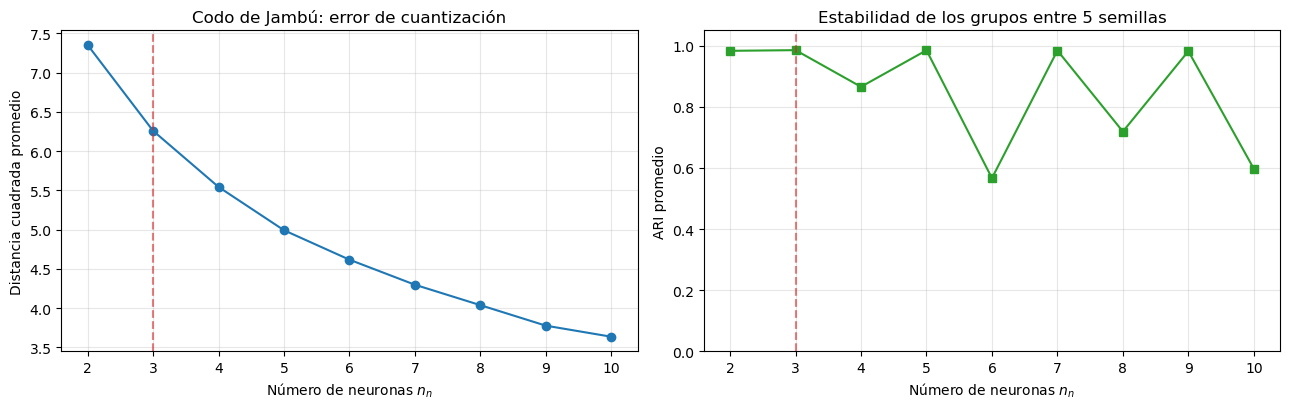

,Error de cuantización,Estabilidad (ARI),Tasa máx. de quiebra en un grupo,% de quiebras en ese grupo
Neuronas,,,,
2,7.351,0.983,11.8%,93.7%
3,6.258,0.985,18.9%,75.9%
4,5.543,0.865,23.0%,58.0%
5,4.991,0.985,30.2%,37.4%
6,4.616,0.567,31.7%,36.8%
7,4.297,0.984,34.4%,37.4%
8,4.037,0.719,38.1%,27.6%
9,3.776,0.982,40.6%,24.7%
10,3.635,0.597,41.0%,24.7%


In [16]:
from sklearn.metrics import adjusted_rand_score

rango_nn = range(2, 11)
semillas = range(5)
filas = []
for nn in rango_nn:
    grupos_semillas, errores = [], []
    for s in semillas:
        W_tmp = entrenar_red_competitiva(X_ent, nn, semilla=s)
        grupos_semillas.append(neurona_ganadora(X_ent, W_tmp))
        errores.append(error_cuantizacion(X_ent, W_tmp))
    ari = np.mean([adjusted_rand_score(grupos_semillas[0], g) for g in grupos_semillas[1:]])
    # Concentración de quiebras: % de las quiebras que caen en el grupo con mayor tasa de quiebra
    g0 = grupos_semillas[0]
    tasas = np.bincount(g0, weights=y_ent, minlength=nn) / np.maximum(np.bincount(g0, minlength=nn), 1)
    captura = y_ent[g0 == np.argmax(tasas)].sum() / y_ent.sum()
    filas.append({"Neuronas": nn, "Error de cuantización": np.mean(errores),
                  "Estabilidad (ARI)": ari, "Tasa máx. de quiebra en un grupo": tasas.max(),
                  "% de quiebras en ese grupo": captura})

tabla_nn = pd.DataFrame(filas).set_index("Neuronas")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
axs[0].plot(tabla_nn.index, tabla_nn["Error de cuantización"], "o-")
axs[0].set_title("Codo de Jambú: error de cuantización")
axs[0].set_xlabel("Número de neuronas $n_n$")
axs[0].set_ylabel("Distancia cuadrada promedio")
axs[1].plot(tabla_nn.index, tabla_nn["Estabilidad (ARI)"], "s-", color="tab:green")
axs[1].set_title("Estabilidad de los grupos entre 5 semillas")
axs[1].set_xlabel("Número de neuronas $n_n$")
axs[1].set_ylabel("ARI promedio")
axs[1].set_ylim(0, 1.05)
for ax in axs:
    ax.axvline(3, color="tab:red", ls="--", alpha=0.6)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(carpeta_img / "rc_numero_neuronas.png", dpi=150)
plt.show()

tabla_nn.style.format({"Error de cuantización": "{:.3f}", "Estabilidad (ARI)": "{:.3f}",
                       "Tasa máx. de quiebra en un grupo": "{:.1%}", "% de quiebras en ese grupo": "{:.1%}"})

**c) Criterio financiero.** En el análisis de quiebra es clásico dividir a las empresas en **tres zonas**, como en el modelo *Z-score* de Altman: zona **segura**, zona **gris** (intermedia) y zona de **peligro**. Tres grupos son fáciles de interpretar y de usar en la práctica (por ejemplo, para decidir a qué empresas dar crédito, a cuáles vigilar y a cuáles rechazar).

**Decisión: $n_n = 3$ neuronas.**
- **Codo de Jambú:** la mayor reducción del error de cuantización ocurre al pasar de 2 a 3 neuronas (de 7.35 a 6.26); después, cada neurona adicional reduce el error cada vez menos.
- **Estabilidad:** con 3 neuronas la red forma prácticamente los mismos grupos con cualquier semilla (ARI = 0.985). Con 4, 6, 8 y 10 neuronas los grupos cambian de una corrida a otra (ARI entre 0.57 y 0.87), así que no son confiables.
- **Concentración de quiebras:** con 3 neuronas el 75.9 % de las quiebras cae en un solo grupo. Con 5 o más neuronas las quiebras se reparten entre varios grupos (menos del 40 % en el grupo de mayor riesgo), lo que hace más difícil interpretar el resultado.
- **Frente a 2 neuronas:** con 2 se separa "riesgo / no riesgo", pero el grupo de riesgo es más grande y menos puro (11.8 % de quiebras contra 18.9 % con 3). La tercera neurona separa una **zona segura** sin quiebras y coincide con las tres zonas del criterio financiero.

<a id="entrenamiento-rc"></a>

### 6.5 Entrenamiento de la red final

In [17]:
nn = 3
alpha = 0.05
epocas = 30

W = entrenar_red_competitiva(X_ent, nn, alpha=alpha, epocas=epocas, semilla=semilla)
grupo_ent = neurona_ganadora(X_ent, W)
grupo_pru = neurona_ganadora(X_pru, W)

print(f"Neuronas: {nn} | α₀ = {alpha} | Épocas: {epocas}")
print(f"Error de cuantización: entrenamiento = {error_cuantizacion(X_ent, W):.3f} | "
      f"prueba = {error_cuantizacion(X_pru, W):.3f}")

Neuronas: 3 | α₀ = 0.05 | Épocas: 30
Error de cuantización: entrenamiento = 6.257 | prueba = 6.294


<a id="posteriori-rc"></a>

### 6.6 Análisis *a posteriori*: distribución de las etiquetas reales en los grupos

Una vez entrenada la red, se revisa la etiqueta real de las empresas que ganó cada neurona.

In [18]:
def tabla_grupos(grupos, y):
    t = pd.crosstab(grupos, y).reindex(index=range(nn), columns=[0, 1], fill_value=0)
    t.columns = ["Sanas", "En quiebra"]
    t["Total"] = t.sum(axis=1)
    t["Tasa de quiebra"] = t["En quiebra"] / t["Total"]
    t["% de todas las quiebras"] = t["En quiebra"] / t["En quiebra"].sum()
    return t

dist_ent = tabla_grupos(grupo_ent, y_ent)

# Nombrar los grupos de menor a mayor tasa de quiebra (zona segura, gris y de peligro)
orden = dist_ent["Tasa de quiebra"].sort_values().index
zonas = ["Zona segura", "Zona gris", "Zona de peligro"]
nombre_grupo = {neurona: f"N{neurona + 1} · {zona}" for neurona, zona in zip(orden, zonas)}

dist_ent = dist_ent.loc[orden]
dist_pru = tabla_grupos(grupo_pru, y_pru).loc[orden]
for t in (dist_ent, dist_pru):
    t.index = [nombre_grupo[i] for i in t.index]

formato = {"Tasa de quiebra": "{:.2%}", "% de todas las quiebras": "{:.1%}"}
print(f"Tasa general de quiebra en entrenamiento: {y_ent.mean():.2%}")
display(dist_ent.style.format(formato).set_caption("Entrenamiento"))
display(dist_pru.style.format(formato).set_caption("Prueba"))

Tasa general de quiebra en entrenamiento: 3.19%


,Sanas,En quiebra,Total,Tasa de quiebra,% de todas las quiebras
N2 · Zona segura,1475,0,1475,0.00%,0.0%
N1 · Zona gris,3248,43,3291,1.31%,24.7%
N3 · Zona de peligro,554,131,685,19.12%,75.3%


,Sanas,En quiebra,Total,Tasa de quiebra,% de todas las quiebras
N2 · Zona segura,415,0,415,0.00%,0.0%
N1 · Zona gris,783,13,796,1.63%,29.5%
N3 · Zona de peligro,121,31,152,20.39%,70.5%


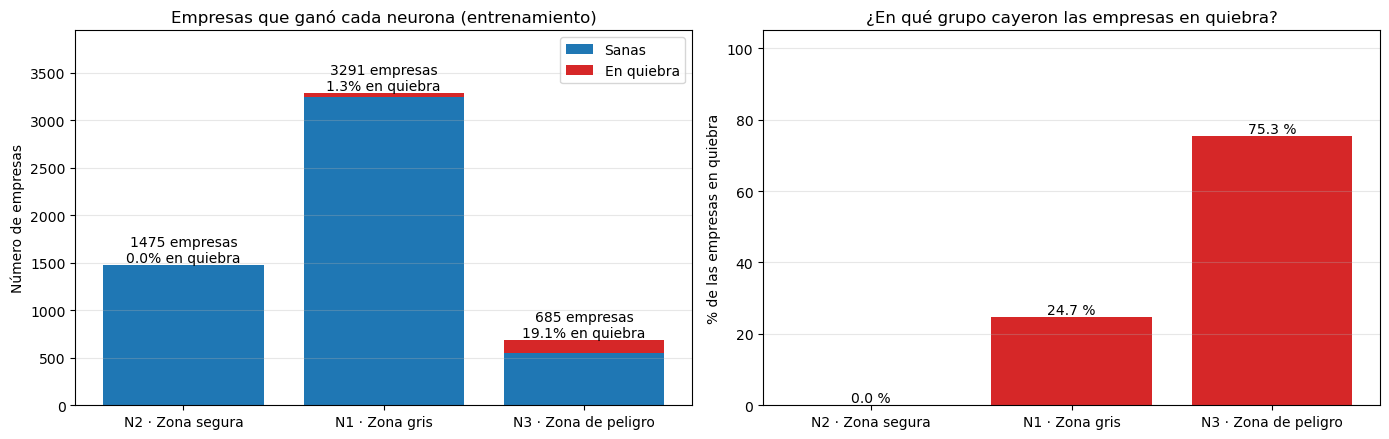

In [19]:
# Gráfica: composición de cada grupo y reparto de las quiebras
etiquetas = list(dist_ent.index)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))

axs[0].bar(etiquetas, dist_ent["Sanas"], color="tab:blue", label="Sanas")
axs[0].bar(etiquetas, dist_ent["En quiebra"], bottom=dist_ent["Sanas"], color="tab:red", label="En quiebra")
for i, (tot, tasa) in enumerate(zip(dist_ent["Total"], dist_ent["Tasa de quiebra"])):
    axs[0].text(i, tot, f"{tot} empresas\n{tasa:.1%} en quiebra", ha="center", va="bottom")
axs[0].set_ylim(0, dist_ent["Total"].max() * 1.2)
axs[0].set_ylabel("Número de empresas")
axs[0].set_title("Empresas que ganó cada neurona (entrenamiento)")
axs[0].legend()

axs[1].bar(etiquetas, dist_ent["% de todas las quiebras"] * 100, color="tab:red")
for i, v in enumerate(dist_ent["% de todas las quiebras"] * 100):
    axs[1].text(i, v, f"{v:.1f} %", ha="center", va="bottom")
axs[1].set_ylim(0, 105)
axs[1].set_ylabel("% de las empresas en quiebra")
axs[1].set_title("¿En qué grupo cayeron las empresas en quiebra?")
for ax in axs:
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(carpeta_img / "rc_distribucion_etiquetas.png", dpi=150)
plt.show()

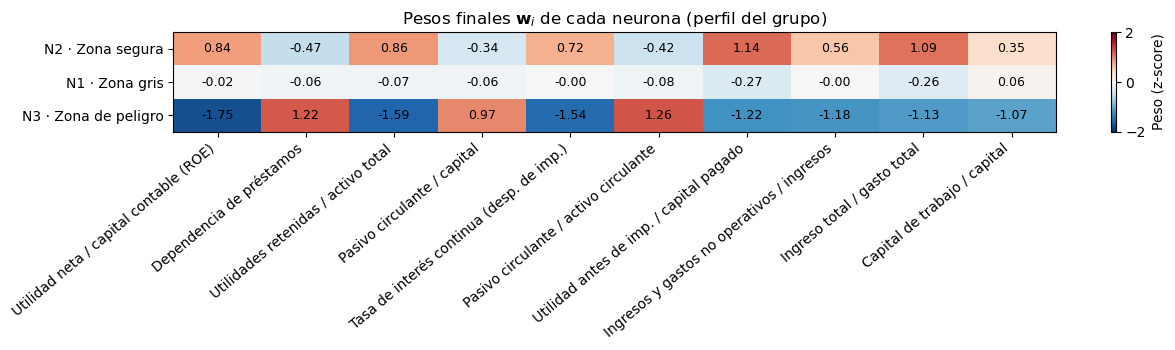

In [20]:
# Perfil financiero de cada grupo: pesos finales (centro de cada neurona) en unidades z
perfil = pd.DataFrame(W[:, orden].T, index=[nombre_grupo[i] for i in orden],
                      columns=[nombres_es.get(v, v) for v in variables_rc])

fig, ax = plt.subplots(figsize=(13, 3.6))
im = ax.imshow(perfil.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(perfil.shape[1]), perfil.columns, rotation=40, ha="right")
ax.set_yticks(range(perfil.shape[0]), perfil.index)
for i in range(perfil.shape[0]):
    for j in range(perfil.shape[1]):
        ax.text(j, i, f"{perfil.iat[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Peso (z-score)")
ax.set_title("Pesos finales $\\mathbf{w}_i$ de cada neurona (perfil del grupo)")
plt.tight_layout()
plt.savefig(carpeta_img / "rc_perfil_grupos.png", dpi=150)
plt.show()

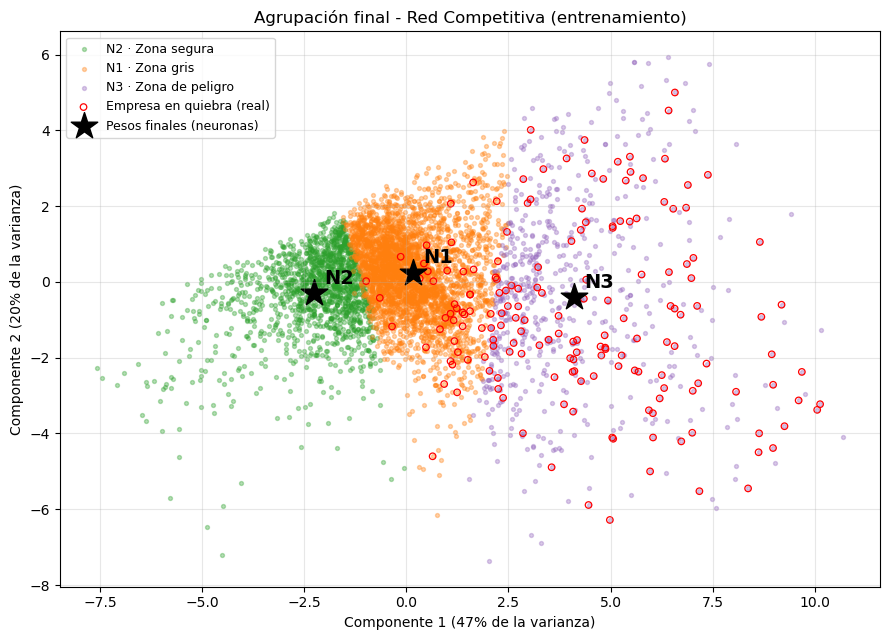

In [21]:
# Vista en 2 dimensiones (componentes principales) de los grupos formados
Xc = X_ent - X_ent.mean(axis=1, keepdims=True)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
P = U[:, :2].T @ Xc                       # Proyección de las empresas
PW = U[:, :2].T @ (W - X_ent.mean(axis=1, keepdims=True))   # Proyección de los pesos
var_exp = S[:2] ** 2 / np.sum(S ** 2)

colores = {orden[0]: "tab:green", orden[1]: "tab:orange", orden[2]: "tab:purple"}
plt.figure(figsize=(9, 6.5))
for g in orden:
    m = grupo_ent == g
    plt.scatter(P[0, m], P[1, m], s=8, alpha=0.35, color=colores[g], label=nombre_grupo[g])
q = y_ent == 1
plt.scatter(P[0, q], P[1, q], s=22, facecolors="none", edgecolors="red", linewidths=0.9, label="Empresa en quiebra (real)")
plt.scatter(PW[0], PW[1], marker="*", s=400, color="black", label="Pesos finales (neuronas)")
for g in orden:
    plt.text(PW[0, g] + 0.25, PW[1, g] + 0.25, f"N{g + 1}", fontsize=14, fontweight="bold")
plt.xlabel(f"Componente 1 ({var_exp[0]:.0%} de la varianza)")
plt.ylabel(f"Componente 2 ({var_exp[1]:.0%} de la varianza)")
plt.title("Agrupación final - Red Competitiva (entrenamiento)")
plt.legend(fontsize=9, loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(carpeta_img / "rc_grupos_pca.png", dpi=150)
plt.show()

**Interpretación de los grupos** (los valores exactos están en las tablas y gráficas anteriores):

- **Zona segura (N2):** 1 475 empresas y **ninguna quiebra** (0 %). Sus pesos muestran rentabilidad por arriba del promedio (ROE ≈ +0.84 *z*, utilidad antes de impuestos / capital ≈ +1.14 *z*) y endeudamiento bajo (dependencia de préstamos ≈ −0.47 *z*).
- **Zona gris (N1):** el grupo más grande (3 291 empresas), con razones financieras cercanas al promedio (pesos cerca de 0). Su tasa de quiebra es de 1.3 %, menor a la tasa general de 3.19 %; ahí cae el 24.7 % de las quiebras.
- **Zona de peligro (N3):** solo 685 empresas (12.6 % del total), pero ahí cae el **75.3 % de las quiebras**. Su tasa de quiebra es de 19.1 %, seis veces la tasa general. Sus pesos tienen **rentabilidad muy baja** (ROE ≈ −1.75 *z*, utilidades retenidas ≈ −1.59 *z*) y **endeudamiento y presión de corto plazo altos** (dependencia de préstamos ≈ +1.22 *z*, pasivo circulante / activo circulante ≈ +1.26 *z*), que es justo el perfil que la teoría financiera asocia con la quiebra.

Es decir, **sin conocer la etiqueta**, la red separó a las empresas con perfil de quiebra. En el conjunto de prueba la distribución es muy parecida: la zona de peligro tiene 20.4 % de quiebras y concentra el 70.5 % de ellas, y la zona segura sigue sin quiebras. Esto indica que los grupos se generalizan a empresas que la red no vio.

<a id="desempeno-rc"></a>

### 6.7 Medidas de desempeño del clasificador

Para usar la red competitiva como clasificador se etiqueta cada neurona con la regla:

$$\hat{y} = \begin{cases} 1 \;(\text{riesgo de quiebra}) & \text{si la tasa de quiebra del grupo ganador} > \text{tasa general de quiebra} \\ 0 \;(\text{sana}) & \text{en otro caso} \end{cases}$$

Las tasas se calculan **solo con el entrenamiento** y la regla se evalúa en el conjunto de **prueba**. Las medidas son:

| Medida | Fórmula | ¿Qué responde? |
|---|---|---|
| Exactitud | $\dfrac{VP + VN}{VP + VN + FP + FN}$ | ¿Qué porcentaje de empresas se clasificó bien? |
| Precisión | $\dfrac{VP}{VP + FP}$ | De las empresas marcadas en riesgo, ¿cuántas quebraron? |
| *Recall* (sensibilidad) | $\dfrac{VP}{VP + FN}$ | De las empresas que quebraron, ¿cuántas detectó? |
| Especificidad | $\dfrac{VN}{VN + FP}$ | De las empresas sanas, ¿cuántas reconoció como sanas? |
| $F_1$ | $\dfrac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$ | Balance entre precisión y *recall* |

donde $VP$ = verdaderos positivos, $VN$ = verdaderos negativos, $FP$ = falsos positivos y $FN$ = falsos negativos (la clase positiva es "quiebra").

In [22]:
def matriz_confusion(y_real, y_pred):
    """[[VN, FP], [FN, VP]] contando directamente (clase positiva = quiebra)."""
    vn = np.sum((y_real == 0) & (y_pred == 0)); fp = np.sum((y_real == 0) & (y_pred == 1))
    fn = np.sum((y_real == 1) & (y_pred == 0)); vp = np.sum((y_real == 1) & (y_pred == 1))
    return np.array([[vn, fp], [fn, vp]])

tasa_general = y_ent.mean()
tasa_grupo = np.bincount(grupo_ent, weights=y_ent, minlength=nn) / np.bincount(grupo_ent, minlength=nn)
neurona_riesgo = (tasa_grupo > tasa_general).astype(int)       # 1 = grupo de riesgo
print("Neuronas etiquetadas como riesgo de quiebra:",
      [nombre_grupo[i] for i in range(nn) if neurona_riesgo[i] == 1])

def medidas(y_real, y_pred):
    vn, fp, fn, vp = matriz_confusion(y_real, y_pred).ravel()
    precision = vp / (vp + fp) if vp + fp > 0 else 0.0
    recall = vp / (vp + fn)
    return {"Exactitud": (vp + vn) / len(y_real), "Precisión": precision, "Recall": recall,
            "Especificidad": vn / (vn + fp),
            "F1": 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0}

pred_ent = neurona_riesgo[grupo_ent]
pred_pru = neurona_riesgo[grupo_pru]

desempeno_rc = pd.DataFrame({
    "Red competitiva (entrenamiento)": medidas(y_ent, pred_ent),
    "Red competitiva (prueba)": medidas(y_pru, pred_pru),
    "Referencia: 'todas sanas' (prueba)": medidas(y_pru, np.zeros_like(y_pru)),
}).T
desempeno_rc.style.format("{:.2%}")

Neuronas etiquetadas como riesgo de quiebra: ['N3 · Zona de peligro']


,Exactitud,Precisión,Recall,Especificidad,F1
Red competitiva (entrenamiento),89.05%,19.12%,75.29%,89.50%,30.50%
Red competitiva (prueba),90.17%,20.39%,70.45%,90.83%,31.63%
Referencia: 'todas sanas' (prueba),96.77%,0.00%,0.00%,100.00%,0.00%


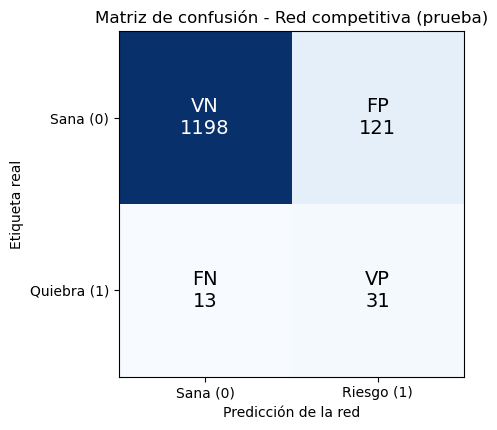

In [23]:
# Matriz de confusión en prueba
mc = matriz_confusion(y_pru, pred_pru)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(mc, cmap="Blues")
textos = [["VN", "FP"], ["FN", "VP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{textos[i][j]}\n{mc[i, j]}", ha="center", va="center", fontsize=14,
                color="white" if mc[i, j] > mc.max() / 2 else "black")
ax.set_xticks([0, 1], ["Sana (0)", "Riesgo (1)"])
ax.set_yticks([0, 1], ["Sana (0)", "Quiebra (1)"])
ax.set_xlabel("Predicción de la red")
ax.set_ylabel("Etiqueta real")
ax.set_title("Matriz de confusión - Red competitiva (prueba)")
plt.tight_layout()
plt.savefig(carpeta_img / "rc_matriz_confusion.png", dpi=150)
plt.show()

**Comprobación: ¿mejora el desempeño con otro número de neuronas?** Para verificar que $n_n = 3$ no sacrifica exactitud ni precisión, se entrena la red con distintos números de neuronas (misma semilla, mismas variables y misma regla de clasificación) y se evalúa en prueba.

In [24]:
filas = []
for n in [2, 3, 4, 5, 6, 8, 10]:
    W_tmp = entrenar_red_competitiva(X_ent, n, alpha=alpha, epocas=epocas, semilla=semilla)
    g_ent = neurona_ganadora(X_ent, W_tmp)
    tasas = np.bincount(g_ent, weights=y_ent, minlength=n) / np.maximum(np.bincount(g_ent, minlength=n), 1)
    riesgo = (tasas > tasa_general).astype(int)
    filas.append({"Neuronas": n, **medidas(y_pru, riesgo[neurona_ganadora(X_pru, W_tmp)])})

comparacion_nn = pd.DataFrame(filas).set_index("Neuronas")
comparacion_nn.style.format("{:.2%}").highlight_max(axis=0, color="#cde6c7")

,Exactitud,Precisión,Recall,Especificidad,F1
Neuronas,,,,,
2,79.09%,12.46%,90.91%,78.70%,21.92%
3,90.17%,20.39%,70.45%,90.83%,31.63%
4,75.57%,10.63%,88.64%,75.13%,18.98%
5,67.94%,8.63%,93.18%,67.10%,15.80%
6,84.08%,14.11%,77.27%,84.31%,23.86%
8,77.26%,11.34%,88.64%,76.88%,20.10%
10,88.70%,18.75%,75.00%,89.16%,30.00%


Con $n_n = 3$ se obtiene la **mayor exactitud (90.2 %), la mayor precisión (20.4 %) y el mayor $F_1$ (0.32)** de todas las configuraciones probadas. Con más neuronas, varios grupos pequeños quedan con una tasa de quiebra apenas mayor a la general y se etiquetan como riesgo, lo que aumenta el *recall* pero llena la predicción de falsos positivos. Esto confirma, con el desempeño, la elección hecha con el conteo de ganadoras, el Codo de Jambú y el criterio financiero.

La precisión no sube mucho más en ningún caso porque es un límite del aprendizaje no supervisado con una clase tan minoritaria (3.2 %): la red agrupa por parecido financiero, no por la etiqueta.

**Análisis del desempeño**

- El modelo de referencia "todas sanas" tiene una exactitud alta solo por el desbalance de la base, pero su *recall* es 0 %: no detecta ninguna quiebra. Por eso la exactitud no basta para evaluar.
- La red competitiva, **sin haber visto nunca la etiqueta**, detecta el 70.5 % de las empresas que quebraron en el conjunto de prueba (31 de 44), con una exactitud de 90.2 % y una especificidad de 90.8 %. Los resultados de entrenamiento y prueba son parecidos, así que el modelo no está sobreajustado.
- La precisión es baja (20.4 %): en la zona de peligro también caen empresas sanas con razones financieras débiles. Es lo esperado en un modelo no supervisado con una clase tan minoritaria: la red agrupa por **parecido financiero**, no por la etiqueta. Aun así, una empresa en la zona de peligro tiene una probabilidad de quiebra varias veces mayor que la tasa general, lo que la hace útil como **señal de alerta temprana**; la red supervisada (ADALINE / perceptrón) de la siguiente sección puede refinar esta clasificación.

<a id="modelo-rc"></a>

### 6.8 Modelo final y uso para empresas nuevas

Se guardan los pesos finales $W_f$, las variables de entrada y la etiqueta de riesgo de cada neurona para que la red se pueda aplicar a las 5 empresas nuevas (sección de predicción).

In [25]:
pesos_finales = pd.DataFrame(W, index=variables_rc, columns=[f"N{i + 1}" for i in range(nn)])
pesos_finales.index.name = "variable"
pesos_finales.to_csv(carpeta_modelos / "red_competitiva_pesos.csv")

resumen_neuronas = pd.DataFrame({
    "neurona": [f"N{i + 1}" for i in range(nn)],
    "zona": [nombre_grupo[i].split(" · ")[1] for i in range(nn)],
    "tasa_quiebra_entrenamiento": tasa_grupo,
    "riesgo_quiebra": neurona_riesgo,
})
resumen_neuronas.to_csv(carpeta_modelos / "red_competitiva_neuronas.csv", index=False)

print("Pesos finales estabilizados (Wf):")
display(pesos_finales.round(3))
display(resumen_neuronas)


def clasificar_red_competitiva(df_normalizado):
    """Clasifica empresas ya normalizadas (mismo tratamiento de la Persona 1).
    Regresa la neurona ganadora, su zona, el vector one-hot y la predicción de riesgo."""
    x = df_normalizado[variables_rc].to_numpy().T
    distancias = np.sum((x[:, :, None] - W[:, None, :]) ** 2, axis=0)
    g = np.argmin(distancias, axis=1)
    salida = np.eye(nn, dtype=int)[g]                 # One-hot (como en clase)
    return pd.DataFrame({"neurona_ganadora": [f"N{i + 1}" for i in g],
                         "zona": [nombre_grupo[i].split(" · ")[1] for i in g],
                         "salida_one_hot": [list(s) for s in salida],
                         "riesgo_quiebra_rc": neurona_riesgo[g]},
                        index=df_normalizado.index)


# Ejemplo de uso con las 5 empresas reservadas (la Persona 4 hace el análisis completo)
nuevas = pd.read_csv(carpeta_tratados / "empresas_nuevas_normalizado.csv", index_col="id_empresa")
clasificar_red_competitiva(nuevas)

Pesos finales estabilizados (Wf):


,N1,N2,N3
variable,,,
Net Income to Stockholder's Equity,-0.023,0.838,-1.752
Borrowing dependency,-0.056,-0.474,1.222
Retained Earnings to Total Assets,-0.068,0.865,-1.588
Current Liabilities/Equity,-0.063,-0.340,0.965
Continuous interest rate (after tax),-0.004,0.715,-1.544
Current Liability to Current Assets,-0.082,-0.425,1.259
Net profit before tax/Paid-in capital,-0.269,1.137,-1.218
Non-industry income and expenditure/revenue,-0.004,0.559,-1.179
Total income/Total expense,-0.265,1.087,-1.130


,neurona,zona,tasa_quiebra_entrenamiento,riesgo_quiebra
0,N1,Zona gris,0.013066,0
1,N2,Zona segura,0.000000,0
2,N3,Zona de peligro,0.191241,1


,neurona_ganadora,zona,salida_one_hot,riesgo_quiebra_rc
id_empresa,,,,
186,N3,Zona de peligro,"[0, 0, 1]",1
3448,N3,Zona de peligro,"[0, 0, 1]",1
5866,N1,Zona gris,"[1, 0, 0]",0
3023,N2,Zona segura,"[0, 1, 0]",0
3062,N1,Zona gris,"[1, 0, 0]",0


**Resumen de la red competitiva**

| Elemento | Valor |
|---|---|
| Variables de entrada | 10 razones financieras (rentabilidad, endeudamiento y liquidez) |
| Número de neuronas | $n_n = 3$ (conteo de ganadoras + Codo de Jambú + estabilidad + zonas financieras + desempeño) |
| Tasa de aprendizaje | $\alpha_0 = 0.05$, decreciente |
| Épocas | 30 |
| Regla de clasificación | Riesgo si la tasa de quiebra de la neurona ganadora es mayor a la tasa general |
| Archivos | `modelos/red_competitiva_pesos.csv`, `modelos/red_competitiva_neuronas.csv` y `red_competitiva.py` (apéndice) |

# Parte supervisada: selección de variables y Perceptrón

Este cuaderno desarrolla tres puntos:

1. Implementación de un **Perceptrón promediado** en Python, entrenado con la etiqueta real de quiebra.
2. Justificación formal de la selección de variables.
3. Construcción y evaluación de un modelo de clasificación supervisado.

Todo lo que se decide (variables, hiperparámetros y umbral) se determina únicamente con los datos de entrenamiento mediante validación cruzada. La base de prueba se utiliza al final para evaluar el modelo

## 1. Carga de datos y funciones de desempeño

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold   # solo para generar los pliegues

np.random.seed(42)
col = "quiebra"
tr = pd.read_csv("datos/tratados/entrenamiento_normalizado.csv", index_col="id_empresa")
te = pd.read_csv("datos/tratados/prueba_normalizado.csv", index_col="id_empresa")
VARS = [c for c in tr.columns if c != col]
X_tr, y_tr = tr[VARS].values, tr[col].values
X_te, y_te = te[VARS].values, te[col].values
print(f"Entrenamiento: {X_tr.shape} ({y_tr.sum()} quiebras) | Prueba: {X_te.shape} ({y_te.sum()} quiebras)")

def matriz_confusion(y, p):
    tp = int(((y==1)&(p==1)).sum()); fp = int(((y==0)&(p==1)).sum())
    fn = int(((y==1)&(p==0)).sum()); tn = int(((y==0)&(p==0)).sum())
    return tp, fp, fn, tn

def metricas(y, p):
    tp, fp, fn, tn = matriz_confusion(y, p)
    exact = (tp+tn)/len(y)
    prec = tp/(tp+fp) if tp+fp else 0.0
    rec = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    return dict(exactitud=exact, precision=prec, recall=rec, f1=f1)

def auc_roc(y, s):
    # AUC por la estadística de Mann-Whitney (rangos)
    r = stats.rankdata(s)
    n1 = y.sum(); n0 = len(y)-n1
    return (r[y==1].sum() - n1*(n1+1)/2) / (n1*n0)

Entrenamiento: (5451, 86) (174 quiebras) | Prueba: (1363, 86) (44 quiebras)


## 2. Implementación del Perceptrón

Se utiliza un **Perceptrón promediado**, basado en el modelo de Rosenblatt. La neurona calcula una combinación lineal de las variables y aplica una función escalón para clasificar cada empresa como sana o en quiebra.

Cuando la predicción es incorrecta, se actualizan los pesos. Se incorpora un peso mayor para los ejemplos de quiebra, ya que esta clase representa una proporción pequeña de la base. Al final se promedian los pesos obtenidos durante el entrenamiento para conseguir una clasificación más estable.

In [5]:
class PerceptronPromediado:
    # Perceptrón de Rosenblatt con promedio de pesos y peso de clase.
    def __init__(self, eta=0.01, epocas=10, peso_quiebra=5.0, seed=42):
        self.eta, self.epocas, self.pq, self.seed = eta, epocas, peso_quiebra, seed
    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        N, d = X.shape; w = np.zeros(d); b = 0.0
        ws = np.zeros(d); bs = 0.0; n = 0
        t = 2*y - 1
        for ep in range(self.epocas):
            for i in rng.permutation(N):
                s = 1 if X[i] @ w + b > 0 else -1
                if s != t[i]:
                    a = self.pq if y[i] == 1 else 1.0
                    w += self.eta*a*t[i]*X[i]; b += self.eta*a*t[i]
                ws += w; bs += b; n += 1
        self.w_, self.b_ = ws/n, bs/n
        return self
    def decision(self, X): return X @ self.w_ + self.b_
    def predict(self, X, umbral=0.0): return (self.decision(X) > umbral).astype(int)


**Entrenamiento.** El Perceptrón aprende a partir de la etiqueta real `quiebra`: 1 representa una empresa que quebró y 0 una empresa sana. Para reducir el efecto del desbalance entre clases, se asigna un peso mayor a los errores cometidos con empresas en quiebra.

In [6]:
# Comprobación sencilla de que el Perceptrón puede entrenarse con las variables de entrada.
prueba = PerceptronPromediado(eta=0.01, epocas=10, peso_quiebra=5.0).fit(X_tr[:, :20], y_tr)
print("Perceptrón entrenado correctamente.")
print(f"Número de pesos aprendidos: {len(prueba.w_)}")


Perceptrón entrenado correctamente.
Número de pesos aprendidos: 20


## 3. Selección de variables (justificación formal)

Partimos de las **86 variables** del tratamiento previo. Se aplica un procedimiento en **tres etapas**, todas calculadas únicamente con los datos de entrenamiento.

### 3.1 Etapa A: relevancia estadística (prueba de hipótesis)

Para cada variable $X_j$ se contrasta $H_0:\mu_{j,\text{quiebra}}=\mu_{j,\text{sana}}$ contra $H_1:\mu_{j,\text{quiebra}}\neq\mu_{j,\text{sana}}$ con la **prueba t de Welch** (no supone varianzas iguales, y los grupos son muy desiguales: 174 vs 5 277):

$$t_j=\frac{\bar x_{j,1}-\bar x_{j,0}}{\sqrt{s_{j,1}^2/n_1+s_{j,0}^2/n_0}}$$

Como se hacen 86 pruebas simultáneas, los $p$-valores se corrigen con **Benjamini-Hochberg** (control de la tasa de falsos descubrimientos, FDR = 5 %). Además se reporta el tamaño de efecto $d$ de Cohen, porque con $n$ grande casi todo es "significativo" y lo importante es *cuánto* separa la variable. Esto se respalda con la **correlación punto-biserial** con la etiqueta, que es matemáticamente la correlación de Pearson entre $X_j$ y $y\in\{0,1\}$, y también con una prueba no paramétrica de **Mann-Whitney** (por si la normalidad falla).

Esto es relevante para ADALINE porque es un modelo **lineal**: una variable con diferencia de medias grande es justamente la que una frontera lineal puede aprovechar.

In [7]:
n1, n0 = (y_tr == 1).sum(), (y_tr == 0).sum()
filas = []
for j, v in enumerate(VARS):
    a, b = X_tr[y_tr == 1, j], X_tr[y_tr == 0, j]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    sp = np.sqrt(((n1-1)*a.var(ddof=1) + (n0-1)*b.var(ddof=1))/(n1+n0-2))
    d = (a.mean() - b.mean())/sp
    r = np.corrcoef(X_tr[:, j], y_tr)[0, 1]
    pmw = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    filas.append((v, t, p, d, r, pmw))
rel = pd.DataFrame(filas, columns=["variable", "t_welch", "p_welch", "d_cohen", "r_puntobiserial", "p_mannwhitney"]).set_index("variable")

def benjamini_hochberg(p):
    p = np.asarray(p); m = len(p); orden = np.argsort(p)
    q = np.empty(m); q[orden] = np.minimum.accumulate((p[orden]*m/np.arange(1, m+1))[::-1])[::-1]
    return np.minimum(q, 1.0)

rel["q_BH"] = benjamini_hochberg(rel["p_welch"])
rel["q_BH_MW"] = benjamini_hochberg(rel["p_mannwhitney"])
rel["abs_t"] = rel["t_welch"].abs()
rel = rel.sort_values("abs_t", ascending=False)
sig = (rel["q_BH"] < 0.05)
print(f"Variables significativas (Welch, FDR 5 %): {sig.sum()} de {len(rel)}")
print(f"Variables significativas (Mann-Whitney, FDR 5 %): {(rel['q_BH_MW'] < 0.05).sum()} de {len(rel)}")
print(f"Con |d| >= 0.5 (efecto al menos moderado): {(rel['d_cohen'].abs() >= 0.5).sum()}")
rel.head(12)[["t_welch", "d_cohen", "r_puntobiserial", "q_BH"]].round(4)

Variables significativas (Welch, FDR 5 %): 74 de 86
Variables significativas (Mann-Whitney, FDR 5 %): 80 de 86
Con |d| >= 0.5 (efecto al menos moderado): 57


,t_welch,d_cohen,r_puntobiserial,q_BH
variable,,,,
Total income/Total expense,-24.0239,-1.0732,-0.1854,0.0
Persistent EPS in the Last Four Seasons,-22.9954,-1.3487,-0.2307,0.0
Net profit before tax/Paid-in capital,-22.3920,-1.2808,-0.2197,0.0
Per Share Net profit before tax (Yuan ¥),-21.8664,-1.2777,-0.2192,0.0
Net Value Per Share (B),-20.9466,-1.0042,-0.1739,0.0
Net Value Per Share (A),-20.8677,-1.0058,-0.1741,0.0
Net worth/Assets,-20.8492,-1.4014,-0.2392,0.0
Debt ratio %,20.8492,1.4014,0.2392,0.0
Net Value Per Share (C),-20.4658,-0.9996,-0.1731,0.0


In [8]:
print("Variables NO significativas tras corregir FDR:")
print(rel.loc[~sig, ["t_welch", "d_cohen", "q_BH"]].round(4).to_string())

Variables NO significativas tras corregir FDR:
                                         t_welch  d_cohen    q_BH
variable                                                         
Net Worth Turnover Rate (times)           1.9863   0.1817  0.0556
No-credit Interval                       -1.9037  -0.2071  0.0663
Interest Expense Ratio                   -1.8039  -0.2401  0.0815
Long-term fund suitability ratio (A)     -1.7481  -0.1319  0.0905
Revenue per person                        1.7103   0.1458  0.0968
Realized Sales Gross Profit Growth Rate  -1.6393  -0.1644  0.1106
Degree of Financial Leverage (DFL)        1.5952   0.2238  0.1194
Current Liabilities/Liability            -1.1084  -0.0844  0.2788
Current Liability to Liability           -1.1084  -0.0844  0.2788
Cash/Current Liability                   -0.9581  -0.1013  0.3474
Inventory/Working Capital                 0.2100   0.0246  0.8438
Accounts Receivable Turnover              0.0622   0.0049  0.9504


### 3.2 Etapa B: redundancia (multicolinealidad)

Muchas razones financieras son casi la misma cantidad (p. ej. las tres versiones del ROA). Variables casi duplicadas **no aportan información nueva** y vuelven inestables los pesos de una neurona lineal (la matriz $\mathbf{X}^\top\mathbf{X}$ queda mal condicionada, es decir, $\kappa=\lambda_{max}/\lambda_{min}$ enorme).

Se usa un filtro **voraz (greedy)** por relevancia: se recorren las variables significativas de mayor a menor $|t|$ y se conserva una solo si su correlación absoluta con **todas** las ya conservadas es menor que $r_{max}$. Así, de cada grupo de variables casi iguales se queda la más relevante.

In [9]:
CORR = tr[VARS].corr().abs()

def filtro_redundancia(candidatas, r_max):
    elegidas = []
    for v in candidatas:                      # candidatas ya ordenadas por |t| decreciente
        if all(CORR.loc[v, s] < r_max for s in elegidas):
            elegidas.append(v)
    return elegidas

candidatas = rel.index[sig].tolist()
for rmax in [0.7, 0.8, 0.9, 0.95, 1.01]:
    sel = filtro_redundancia(candidatas, rmax)
    M = tr[sel].values
    print(f"r_max = {rmax:>4}: {len(sel):2d} variables | número de condición de la matriz de correlación = {np.linalg.cond(np.corrcoef(M.T)):,.0f}")

r_max =  0.7: 36 variables | número de condición de la matriz de correlación = 150
r_max =  0.8: 39 variables | número de condición de la matriz de correlación = 722
r_max =  0.9: 53 variables | número de condición de la matriz de correlación = 5,996
r_max = 0.95: 58 variables | número de condición de la matriz de correlación = 7,067
r_max = 1.01: 74 variables | número de condición de la matriz de correlación = 1,352,346,942,364,232,192


### 3.3 Etapa C: elegir el umbral $r_{max}$ y el número de variables con validación cruzada

Los pasos A y B dan un **orden** y una **lista sin redundancia**, pero no dicen dónde cortar. Eso se decide con **validación cruzada estratificada de 5 pliegues repetida 3 veces** (solo con entrenamiento), usando como criterio el **AUC** (no depende del umbral, así que compara limpiamente subconjuntos de variables) y el **F1** de la clase "quiebra" con su mejor umbral.

El filtro y el ranking se recalculan **dentro de cada pliegue** para no filtrar información del pliegue de validación.

In [10]:
def ranking_pliegue(X, y):
    # |t| y p-valor de Welch calculados solo con el pliegue de entrenamiento.
    t, p = stats.ttest_ind(X[y == 1], X[y == 0], equal_var=False, axis=0)
    return np.abs(t), p

def seleccionar_idx(X, y, r_max, k=None, alfa=0.05):
    # Procedimiento A (Welch + BH) y B (filtro de redundancia), dentro del pliegue.
    abs_t, p = ranking_pliegue(X, y)
    q = benjamini_hochberg(p)
    orden = [j for j in np.argsort(-abs_t) if q[j] < alfa]
    C = np.abs(np.corrcoef(X.T)); sel = []
    for j in orden:
        if all(C[j, s] < r_max for s in sel): sel.append(j)
        if k and len(sel) == k: break
    return np.array(sel)

def mejor_f1(y, s, n=120):
    umbrales = np.quantile(s, np.linspace(0.90, 0.997, n))
    f = [metricas(y, (s > u).astype(int))["f1"] for u in umbrales]
    i = int(np.argmax(f)); return f[i], umbrales[i]

def cv_oof(r_max, lam=None, pq=5.0, semillas=(42, 1, 2), k=None):
    # Validación cruzada del Perceptrón; lam se conserva solo para compatibilidad con la llamada previa.
    aucs, f1s = [], []
    for sem in semillas:
        oof = np.zeros(len(y_tr))
        for a, b in StratifiedKFold(5, shuffle=True, random_state=sem).split(X_tr, y_tr):
            idx = seleccionar_idx(X_tr[a], y_tr[a], r_max, k)
            modelo = PerceptronPromediado(0.01, 10, pq, seed=sem).fit(X_tr[a][:, idx], y_tr[a])
            oof[b] = modelo.decision(X_tr[b][:, idx])
        aucs.append(auc_roc(y_tr, oof)); f1s.append(mejor_f1(y_tr, oof)[0])
    return np.mean(aucs), np.mean(f1s)

filas = []
for r_max in [0.7, 0.8, 0.85, 0.9, 0.95, 1.01]:
    auc, f1 = cv_oof(r_max, pq=5.0)
    filas.append((r_max, auc, f1))
cv_rmax = pd.DataFrame(filas, columns=["r_max", "AUC_cv", "F1_cv"])
print(cv_rmax.round(4).to_string(index=False))


 r_max  AUC_cv  F1_cv
  0.70  0.9138 0.4279
  0.80  0.9205 0.4365
  0.85  0.9191 0.4366
  0.90  0.9219 0.4458
  0.95  0.9220 0.4441
  1.01  0.9218 0.4619


 k_variables  AUC_cv  F1_cv
           5  0.9223 0.4055
          10  0.9220 0.4091
          15  0.9247 0.4142
          20  0.9211 0.4072
          30  0.9192 0.4140
          40  0.9172 0.4277
          53  0.9202 0.4415


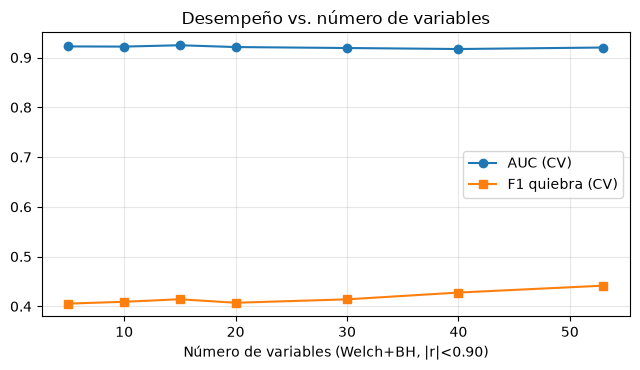

In [11]:
idx_ref = seleccionar_idx(X_tr, y_tr, 0.90)
filas = []
for k in [5, 10, 15, 20, 30, 40, len(idx_ref)]:
    auc, f1 = cv_oof(0.90, 30, 5.0, k=k)
    filas.append((k, auc, f1))
cv_k = pd.DataFrame(filas, columns=["k_variables", "AUC_cv", "F1_cv"])
print(cv_k.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(cv_k.k_variables, cv_k.AUC_cv, "o-", label="AUC (CV)")
ax.plot(cv_k.k_variables, cv_k.F1_cv, "s-", label="F1 quiebra (CV)")
ax.set_xlabel("Número de variables (Welch+BH, |r|<0.90)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Desempeño vs. número de variables"); plt.tight_layout(); plt.show()

### 3.4 Selección final

In [12]:
R_MAX = 0.90
sel_final = filtro_redundancia(candidatas, R_MAX)
idx_final = [VARS.index(v) for v in sel_final]
print(f"Variables finales: {len(sel_final)} de {len(VARS)}")
tabla_sel = rel.loc[sel_final, ["d_cohen", "r_puntobiserial", "q_BH"]].round(3)
print(tabla_sel.head(15).to_string())
eliminadas_red = [v for v in candidatas if v not in sel_final]
print(f"\nDescartadas por redundancia (|r|>={R_MAX}): {len(eliminadas_red)} | por no significativas: {(~sig).sum()}")

Variables finales: 53 de 86
                                                         d_cohen  r_puntobiserial  q_BH
variable                                                                               
Total income/Total expense                                -1.073           -0.185   0.0
Persistent EPS in the Last Four Seasons                   -1.349           -0.231   0.0
Net Value Per Share (B)                                   -1.004           -0.174   0.0
Net worth/Assets                                          -1.401           -0.239   0.0
ROA(C) before interest and depreciation before interest   -1.412           -0.241   0.0
Operating profit/Paid-in capital                          -0.928           -0.161   0.0
Borrowing dependency                                       1.821            0.305   0.0
Total debt/Total net worth                                 1.778            0.298   0.0
Retained Earnings to Total Assets                         -1.640           -0.277   0.0
Work

**Justificación resumida de la selección**

1. **Relevancia (Etapa A).** Solo se consideran variables cuya diferencia de medias entre quiebra y sana es estadísticamente distinta de cero con control de FDR al 5 %. Las que quedan fuera no tienen evidencia de separar las clases y solo añadirían ruido a la neurona.
2. **No redundancia (Etapa B).** Entre variables con $|r|\ge0.90$ se conserva la más relevante. Esto reduce el número de condición de la matriz de datos, de modo que el descenso por gradiente converge más rápido y los pesos son interpretables (no se reparte el mismo efecto entre tres versiones del ROA).
3. **Corte empírico (Etapa C).** El valor $r_{max}=0.90$ no se eligió por intuición: fue el que dio mejor F1 y AUC en validación cruzada con todo el procedimiento repetido dentro de cada pliegue.
4. **Coherencia financiera.** Las variables mejor posicionadas son rentabilidad sobre capital/activos (menores en quiebra) y endeudamiento/dependencia de préstamos (mayores en quiebra), lo que coincide con la teoría de solvencia.

## 4. Ajuste del Perceptrón y del umbral de clasificación

Con las variables seleccionadas se entrena el Perceptrón y se revisa su desempeño mediante validación cruzada, utilizando únicamente el conjunto de entrenamiento.

Como las empresas en quiebra son una minoría, la exactitud por sí sola puede ser engañosa. Por eso también se consideran la precisión y el recall de la clase quiebra. Para elegir el umbral se utiliza el **F0.5**, que da mayor importancia a la precisión, manteniendo un recall mínimo de 30 % para evitar que el modelo simplemente deje de detectar quiebras.


In [13]:
def oof_scores(idx, pq=5.0, semillas=(42, 1, 2), eta=0.01, epocas=10):
    salidas = []
    for sem in semillas:
        oof = np.zeros(len(y_tr))
        for a, b in StratifiedKFold(5, shuffle=True, random_state=sem).split(X_tr, y_tr):
            modelo = PerceptronPromediado(eta, epocas, pq, seed=sem).fit(X_tr[a][:, idx], y_tr[a])
            oof[b] = modelo.decision(X_tr[b][:, idx])
        salidas.append(oof)
    return salidas

# Se comparan distintos pesos para dar mayor importancia a las empresas en quiebra.
filas = []
for pq in [1, 3, 5, 8, 12]:
    oofs = oof_scores(idx_final, pq=pq)
    filas.append((pq, np.mean([auc_roc(y_tr, o) for o in oofs]), np.mean([mejor_f1(y_tr, o)[0] for o in oofs])))
grid = pd.DataFrame(filas, columns=["peso_quiebra", "AUC_cv", "F1_cv"]).sort_values("F1_cv", ascending=False)
print(grid.round(4).to_string(index=False))


 peso_quiebra  AUC_cv  F1_cv
            8  0.9235 0.4478
           12  0.9243 0.4478
            5  0.9217 0.4428
            3  0.9171 0.4370
            1  0.8884 0.3968


Peso para la clase quiebra elegido: 8.0
Umbral elegido (F0.5 máximo con recall >= 30 %): theta = 0.995
       exactitud  precision  recall      f1     f05
0.995     0.9558     0.3698  0.5441  0.4403  0.3952


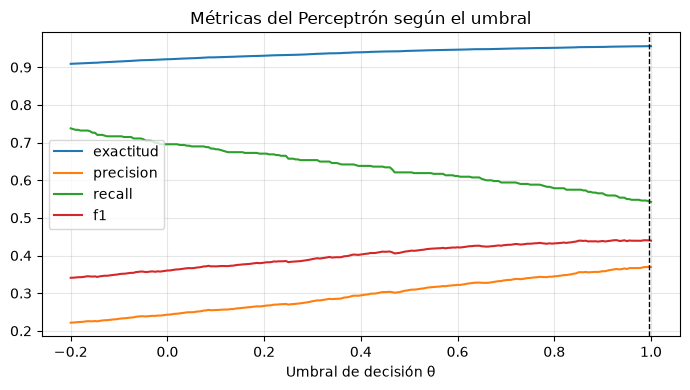

In [14]:
PQ = float(grid.iloc[0]["peso_quiebra"])
print(f"Peso para la clase quiebra elegido: {PQ}")

# Barrido del umbral sobre predicciones fuera de muestra (promedio de 3 repeticiones).
oofs = oof_scores(idx_final, pq=PQ)
umbrales = np.linspace(-0.2, 1.0, 241)
curva = []
for u in umbrales:
    m = np.mean([[metricas(y_tr, (o > u).astype(int))[k] for k in ("exactitud", "precision", "recall", "f1")] for o in oofs], axis=0)
    curva.append(m)
curva = pd.DataFrame(curva, columns=["exactitud", "precision", "recall", "f1"], index=umbrales)
curva["f05"] = 1.25*curva.precision*curva.recall/(0.25*curva.precision + curva.recall + 1e-12)
ok = curva[curva.recall >= 0.30]
UMBRAL = ok.f05.idxmax()
print(f"Umbral elegido (F0.5 máximo con recall >= 30 %): theta = {UMBRAL:.3f}")
print(curva.loc[[UMBRAL]].round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 4))
for c in ['exactitud','precision','recall','f1']: ax.plot(curva.index, curva[c], label=c)
ax.axvline(UMBRAL, color="k", ls="--", lw=1); ax.set_xlabel("Umbral de decisión θ"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Métricas del Perceptrón según el umbral"); plt.tight_layout(); plt.show()


## 5. Modelo final y evaluación en prueba

Se entrena el **Perceptrón promediado** con todas las observaciones del conjunto de entrenamiento y las variables seleccionadas. Después se evalúa una sola vez con el conjunto de prueba, que no se utilizó para elegir las variables ni ajustar el modelo.


In [15]:
Xs_tr, Xs_te = X_tr[:, idx_final], X_te[:, idx_final]
NV = len(idx_final)

modelo_final = PerceptronPromediado(eta=0.01, epocas=10, peso_quiebra=PQ).fit(Xs_tr, y_tr)
s_final = modelo_final.decision(Xs_te)
p_final = (s_final > UMBRAL).astype(int)

resultados = {"Perceptrón promediado (variables seleccionadas)": {**metricas(y_te, p_final), "AUC": auc_roc(y_te, s_final)}}
tabla = pd.DataFrame(resultados).T
print(f"Modelo evaluado: Perceptrón promediado | Variables: {NV}")
print("Resultados en prueba:")
print(tabla.round(4))


Modelo evaluado: Perceptrón promediado | Variables: 53
Resultados en prueba:
                                                 exactitud  precision  recall  \
Perceptrón promediado (variables seleccionadas)     0.9596     0.4154  0.6136   

                                                     f1     AUC  
Perceptrón promediado (variables seleccionadas)  0.4954  0.9575  


Matriz de confusión (prueba):
                 Pred. sana   Pred. quiebra
Real sana            1281         38
Real quiebra           17         27


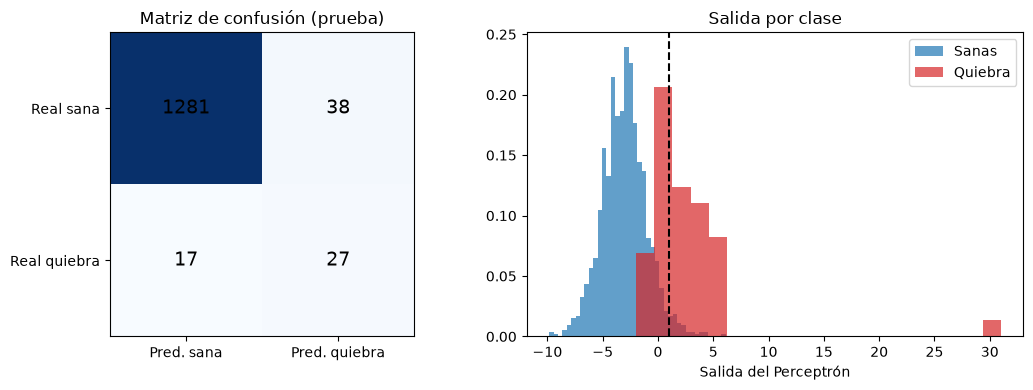

In [16]:
tp, fp, fn, tn = matriz_confusion(y_te, p_final)
print(f"Matriz de confusión (prueba):\n                 Pred. sana   Pred. quiebra\nReal sana        {tn:8d}   {fp:8d}\nReal quiebra     {fn:8d}   {tp:8d}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].imshow([[tn, fp], [fn, tp]], cmap="Blues")
for (i, j), v in np.ndenumerate([[tn, fp], [fn, tp]]): axs[0].text(j, i, v, ha="center", va="center", fontsize=14)
axs[0].set_xticks([0, 1], ["Pred. sana", "Pred. quiebra"]); axs[0].set_yticks([0, 1], ["Real sana", "Real quiebra"]); axs[0].set_title("Matriz de confusión (prueba)")
axs[1].hist(s_final[y_te == 0], bins=40, alpha=.7, label="Sanas", density=True)
axs[1].hist(s_final[y_te == 1], bins=20, alpha=.7, label="Quiebra", density=True, color="tab:red")
axs[1].axvline(UMBRAL, color="k", ls="--"); axs[1].set_xlabel("Salida del Perceptrón"); axs[1].legend(); axs[1].set_title("Salida por clase")
plt.tight_layout(); plt.show()


In [17]:
pesos = pd.Series(modelo_final.w_, index=sel_final).sort_values(key=np.abs, ascending=False)
print("Variables con mayor peso absoluto en el Perceptrón:")
print(pesos.head(10).round(4).to_string())


Variables con mayor peso absoluto en el Perceptrón:
Liability-Assets Flag                          0.9497
Current Liability to Assets                    0.6712
Inventory and accounts receivable/Net value   -0.6697
Persistent EPS in the Last Four Seasons       -0.6378
Operating profit/Paid-in capital               0.5498
Cash Flow to Sales                            -0.5458
Revenue Per Share (Yuan ¥)                    -0.5310
Operating Profit Rate                          0.4399
Total Asset Turnover                           0.4341
Net worth/Assets                              -0.4231


## Conclusiones

En este trabajo utilicé un **Perceptrón promediado** para desarrollar un modelo de clasificación supervisado que permitiera identificar empresas con riesgo de quiebra a partir de sus indicadores financieros.

Primero realicé una selección de variables, pasando de 86 a 53, utilizando pruebas estadísticas y análisis de correlación para conservar las que aportaban información relevante y evitar datos repetidos.

En los resultados, el modelo obtuvo una exactitud de **95.96 %**, una precisión de **41.54 %**, un recall de **61.36 %** y un AUC de **0.9575**. Aunque la exactitud fue alta, la precisión fue menor, lo que indica que todavía existen falsas alarmas al clasificar empresas como posibles quiebras.

En general, considero que el modelo logró identificar patrones relacionados con el riesgo de quiebra, pero también entendí que no basta con obtener una exactitud alta. Es importante revisar qué tan bien identifica realmente las empresas que quiebran y qué aspectos se pueden mejorar para obtener predicciones más confiables.